## Exploración de los datos
Realiza un análisis exploratorio del conjunto de datos que incluya:
<br>
        • Dimensiones del dataset. <br>
        • Tipos de variables. <br>
        • Valores nulos. <br>
        • Registros duplicados. <br> 
        • Estadísticos descriptivos. <br> 
        • Visualizaciones que permitan comprender la información. <br> 
    </br>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "steam-200k.csv"

df_raw = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "tamber/steam-video-games",
  file_path,
  pandas_kwargs={"header": None}
)

df = df_raw.copy()

print("First 5 records:", df.head())



First 5 records:            0                           1         2      3  4
0  151603712  The Elder Scrolls V Skyrim  purchase    1.0  0
1  151603712  The Elder Scrolls V Skyrim      play  273.0  0
2  151603712                   Fallout 4  purchase    1.0  0
3  151603712                   Fallout 4      play   87.0  0
4  151603712                       Spore  purchase    1.0  0


In [3]:
print(df.columns.tolist())

[0, 1, 2, 3, 4]


Podemos observar que la base de datos no contiene titulos de columna, por lo que pasaremos a proponer el titulo relevante

In [4]:
df.shape

(200000, 5)

El dataset contiene 200.000 registros y 5 columnas. Cada registro corresponde a una interacción de un usuario con un videojuego; por tanto, un mismo usuario puede aparecer en varias filas.

In [5]:
df[0].nunique()

12393

El conjunto de datos contiene 200.000 registros distribuidos en 5 columnas. La primera columna presenta 12.393 identificadores de usuario distintos. Por tanto, los registros corresponden a interacciones de esos usuarios con videojuegos, y no a 200.000 usuarios diferentes.

In [6]:
['user_id', 'game', 'behavior_name', 'behavior_metric' ]

['user_id', 'game', 'behavior_name', 'behavior_metric']

Realizamos una propuesta de titulo para categorizar cada columna segun lo que representan los datos, y se elimina la columna 5ta debido a que no aporta valor estadistico a los datos. 

In [7]:
df[4].value_counts(dropna=False)

4
0    200000
Name: count, dtype: int64

La quinta columna es constante: contiene el valor 0 en los 200.000 registros. Por tanto, no permite diferenciar las interacciones ni los usuarios y se excluirá de las variables utilizadas para la segmentación.

In [8]:
df = df.drop(columns=[4]) #Eliminamos columna sobrante

In [9]:
df.columns = ['user_id', 'game', 'behavior_name', 'behavior_metric'] #Asignamos los nombres a las columnas que conservamos

In [10]:
df.shape
df.head()

,user_id,game,behavior_name,behavior_metric
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0
1,151603712,The Elder Scrolls V Skyrim,play,273.0
2,151603712,Fallout 4,purchase,1.0
3,151603712,Fallout 4,play,87.0
4,151603712,Spore,purchase,1.0


Pasamos a identificar los tipos de variables de los datos

In [11]:
df.dtypes

user_id              int64
game                object
behavior_name       object
behavior_metric    float64
dtype: object

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 4 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   user_id          200000 non-null  int64  
 1   game             200000 non-null  object 
 2   behavior_name    200000 non-null  object 
 3   behavior_metric  200000 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 6.1+ MB


No se identificaron valores nulos en las cuatro columnas analizadas, según la salida de df.info().

In [13]:
df.duplicated().sum() #Buscamos identificar dupicados

np.int64(707)

Se identificaron 707 filas que repiten los valores de las cuatro columnas de una fila anterior.

In [14]:
df[df.duplicated(keep=False)].sort_values(
    ['user_id', 'game', 'behavior_name', 'behavior_metric']
).head(10)

,user_id,game,behavior_name,behavior_metric
142904,561758,Sid Meier's Civilization IV,purchase,1.0
142905,561758,Sid Meier's Civilization IV,purchase,1.0
142906,561758,Sid Meier's Civilization IV Beyond the Sword,purchase,1.0
142907,561758,Sid Meier's Civilization IV Beyond the Sword,purchase,1.0
142908,561758,Sid Meier's Civilization IV Colonization,purchase,1.0
142909,561758,Sid Meier's Civilization IV Colonization,purchase,1.0
142910,561758,Sid Meier's Civilization IV Warlords,purchase,1.0
142911,561758,Sid Meier's Civilization IV Warlords,purchase,1.0
89867,1936551,Sid Meier's Civilization IV Colonization,purchase,1.0
90025,1936551,Sid Meier's Civilization IV Colonization,purchase,1.0


In [15]:
df.loc[df.duplicated(), 'behavior_name'].value_counts()


behavior_name
purchase    707
Name: count, dtype: int64

Se identificaron 707 filas duplicadas exactas, todas asociadas al comportamiento purchase. Estas repiten los valores de las cuatro columnas de un registro anterior. Su tratamiento se decidirá en la etapa de preparación de datos.

In [16]:
df[['game', 'behavior_name']].describe()

,game,behavior_name
count,200000,200000
unique,5155,2
top,Dota 2,purchase
freq,9682,129511


Se identificaron 5.155 videojuegos distintos. Dota 2 es el título con mayor presencia en el dataset, con 9.682 registros. El comportamiento más frecuente es purchase, con 129.511 registros. Estos conteos corresponden a filas, no a usuarios únicos.

In [17]:
df.groupby('behavior_name')['behavior_metric'].describe()

,count,mean,std,min,25%,50%,75%,max
behavior_name,,,,,,,,
play,70489.0,48.878063,229.335236,0.1,1.0,4.5,19.1,11754.0
purchase,129511.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0


La media de horas por registro de juego (48,88) es considerablemente mayor que la mediana (4,5). Esta diferencia sugiere que los registros con muchas horas elevan el promedio, por lo que conviene complementar su interpretación con la mediana y los cuartiles.

Identificamos 707 duplicados exactos, todos de "purchase". Necesitamos una tabla por usuario, actualmente cada fila representa una interaccion usuario, video juego. Para segmentar usuaario se utilizara una una fila por usuario y variables que definan su comportamiento. 

In [18]:
purchase = df[df['behavior_name'] == 'purchase']

duplicados = purchase[purchase.duplicated(keep=False)]

duplicados.sort_values(['user_id', 'game']).head(10)

,user_id,game,behavior_name,behavior_metric
142904,561758,Sid Meier's Civilization IV,purchase,1.0
142905,561758,Sid Meier's Civilization IV,purchase,1.0
142906,561758,Sid Meier's Civilization IV Beyond the Sword,purchase,1.0
142907,561758,Sid Meier's Civilization IV Beyond the Sword,purchase,1.0
142908,561758,Sid Meier's Civilization IV Colonization,purchase,1.0
142909,561758,Sid Meier's Civilization IV Colonization,purchase,1.0
142910,561758,Sid Meier's Civilization IV Warlords,purchase,1.0
142911,561758,Sid Meier's Civilization IV Warlords,purchase,1.0
89867,1936551,Sid Meier's Civilization IV Colonization,purchase,1.0
90025,1936551,Sid Meier's Civilization IV Colonization,purchase,1.0


Podemos identificar que hay titulos asociados a compras que corresponden al mismo usuario, por lo tanto se aplicara el metodo "drop_duplicates" con keep=first para conservar la primera aparacion y eliminando las copias posteriores

In [19]:
df_limpio = df.drop_duplicates(keep='first')

print("Filas antes:", len(df))
print("Filas después:", len(df_limpio))
print("Filas eliminadas:", len(df) - len(df_limpio))
print("Duplicados restantes:", df_limpio.duplicated().sum())

Filas antes: 200000
Filas después: 199293
Filas eliminadas: 707
Duplicados restantes: 0


Se eliminaron 707 registros duplicados exactos, todos correspondientes al comportamiento purchase, conservando una aparición de cada registro. El dataset resultante contiene 199.293 filas y no presenta duplicados exactos.



In [20]:
#filtramos los registros de juego
play = df_limpio[df_limpio['behavior_name'] == 'play']

#sumar horas de cada usuario
horas_por_usuario = (
    play.groupby('user_id')['behavior_metric']
    .sum()
)

horas_por_usuario.head()

user_id
5250       225.5
76767     1227.0
86540      255.0
144736       0.1
181212       2.2
Name: behavior_metric, dtype: float64

Encontramos con este resultado una primera caracteristica para describir a cada usuario: el total de horas registradas.

Buscando indentificar en cuantos juegos distintos tiene registros de juego.

In [21]:
#juego distintos por usuario

horas_por_usuario_juego = (
    play.groupby(['user_id', 'game'], as_index=False)['behavior_metric']
    .sum()
    .rename(columns={'behavior_metric': 'horas_jugadas'})
)

horas_por_usuario_juego.head(10)

,user_id,game,horas_jugadas
0,5250,Alien Swarm,4.9
1,5250,Cities Skylines,144.0
2,5250,Deus Ex Human Revolution,62.0
3,5250,Dota 2,0.2
4,5250,Portal 2,13.6
5,5250,Team Fortress 2,0.8
6,76767,Age of Empires II HD Edition,13.1
7,76767,Alien Swarm,0.8
8,76767,Banished,24.0
9,76767,Call of Duty Black Ops,22.0


In [22]:
horas_por_usuario_juego.nunique

<bound method DataFrame.nunique of          user_id                          game  horas_jugadas
0           5250                   Alien Swarm            4.9
1           5250               Cities Skylines          144.0
2           5250      Deus Ex Human Revolution           62.0
3           5250                        Dota 2            0.2
4           5250                      Portal 2           13.6
...          ...                           ...            ...
70472  309434439                        Dota 2            0.8
70473  309554670             Mitos.is The Game            5.9
70474  309626088  Age of Empires II HD Edition            6.7
70475  309824202                        Dota 2            0.7
70476  309903146                        Dota 2            0.2

[70477 rows x 3 columns]>

Realizamos un analisis estadisitico descriptivo para conocer mas en detalle los rango de los usuario en cuanto a horas jugas por los mismo y la cantidad de usuario con registros play

In [23]:
horas_por_usuario_juego['horas_jugadas'].describe()

count    70477.000000
mean        48.886386
std        229.353917
min          0.100000
25%          1.000000
50%          4.500000
75%         19.100000
max      11754.000000
Name: horas_jugadas, dtype: float64

In [24]:
horas_por_usuario.describe()

count    11350.000000
mean       303.556458
std        789.541803
min          0.100000
25%          2.300000
50%         19.500000
75%        198.975000
max      11754.000000
Name: behavior_metric, dtype: float64

La media de 303,56 horas es mucho mayor que la mediana de 19,5: los usuarios con muchas horas acumuladas elevan el promedio. Estos resultados corresponden a los 11.350 usuarios con registros play, no a los 12.393 usuarios del dataset completo. No se esta asignando cero horas a los demás.

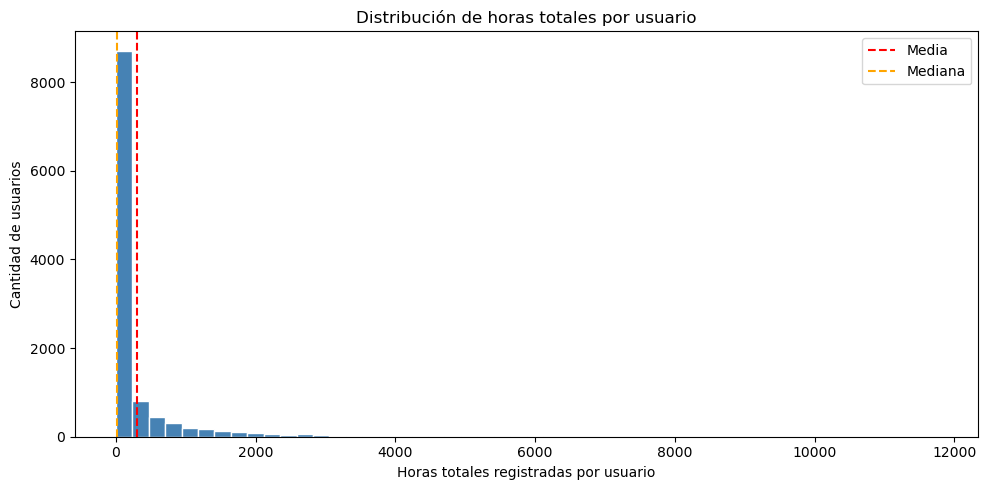

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    horas_por_usuario,
    bins=50,
    color='steelblue',
    edgecolor='white'
)

plt.axvline(
    horas_por_usuario.mean(),
    color='red',
    linestyle='--',
    label='Media'
)

plt.axvline(
    horas_por_usuario.median(),
    color='orange',
    linestyle='--',
    label='Mediana'
)

plt.title('Distribución de horas totales por usuario')
plt.xlabel('Horas totales registradas por usuario')
plt.ylabel('Cantidad de usuarios')
plt.legend()
plt.tight_layout()
plt.show()

Las horas totales registradas por usuario presentan una distribución asimétrica hacia la derecha. La mayoría de los usuarios se concentra en valores bajos respecto al rango observado, mientras que una minoría acumula muchas horas y eleva la media por encima de la mediana.

In [26]:
juegos_por_usuario = play.groupby('user_id')['game'].nunique()

juegos_por_usuario.head()

user_id
5250       6
76767     20
86540     15
144736     1
181212     2
Name: game, dtype: int64

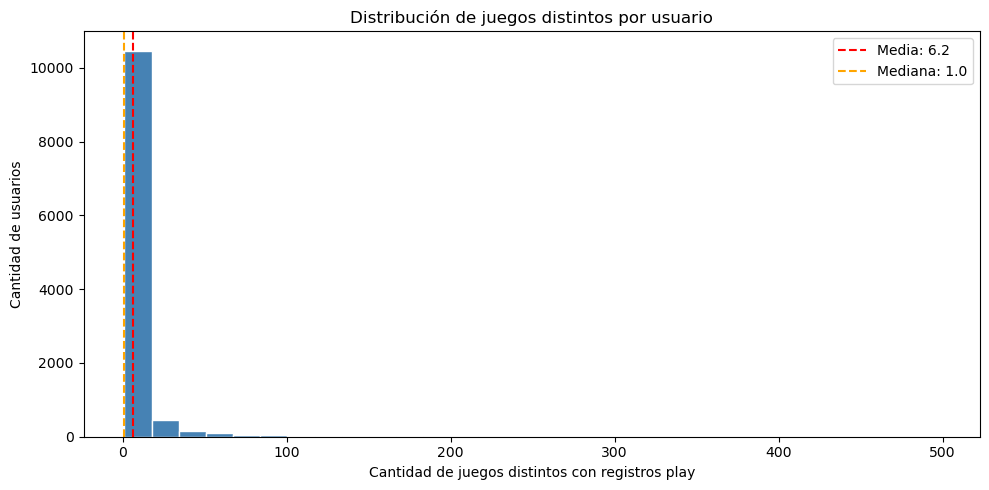

In [27]:
plt.figure(figsize=(10, 5))

plt.hist(
    juegos_por_usuario,
    bins=30,
    color='steelblue',
    edgecolor='white'
)

plt.axvline(
    juegos_por_usuario.mean(),
    color='red',
    linestyle='--',
    label=f'Media: {juegos_por_usuario.mean():.1f}'
)

plt.axvline(
    juegos_por_usuario.median(),
    color='orange',
    linestyle='--',
    label=f'Mediana: {juegos_por_usuario.median():.1f}'
)

plt.title('Distribución de juegos distintos por usuario')
plt.xlabel('Cantidad de juegos distintos con registros play')
plt.ylabel('Cantidad de usuarios')
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
juegos_por_usuario.describe()


count    11350.000000
mean         6.209427
std         17.754906
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max        498.000000
Name: game, dtype: float64

Entre los usuarios con registros play, la mediana es de un juego distinto y el promedio es de 6,21. Al menos el 75% tiene registros de juego en tres títulos o menos. La distribución presenta una cola hacia valores altos, con un máximo de 498 juegos por usuario.

Continuamos con la preparacion de datos, construyendo una tabla provisional con los usuario que tienen registros "play"

In [29]:
usuarios_play = pd.concat(
    [
        horas_por_usuario.rename('horas_totales'),
        juegos_por_usuario.rename('juegos_jugados')
    ],
    axis=1
)

usuarios_play.head()

,horas_totales,juegos_jugados
user_id,,
5250,225.5,6
76767,1227.0,20
86540,255.0,15
144736,0.1,1
181212,2.2,2


Se agregaron los registros de juego a nivel de usuario mediante dos variables: horas totales registradas y cantidad de videojuegos distintos con registros play. Estas variables describen el volumen de juego y la diversidad de títulos jugados. Se combinaron utilizando user_id como identificador.

In [30]:
print("Dimensiones:", usuarios_play.shape)
print(usuarios_play.isna().sum())

Dimensiones: (11350, 2)
horas_totales     0
juegos_jugados    0
dtype: int64


Pasamos a incorporar los juego bajo 'purchase', primero contamos los juegos distintos registros 'purchase' por usuario usando el dataset limpio

In [31]:
purchase = df_limpio[df_limpio['behavior_name'] == 'purchase']

juegos_comprados = (
    purchase.groupby('user_id')['game']
    .nunique()
    .rename('juegos_comprados')
)

usuarios = usuarios_play.join(juegos_comprados, how='left')

Se incorporó la cantidad de juegos distintos registrados como purchase para complementar las variables de juego con una medida de adquisición de títulos. Se mantuvo como población de análisis a los usuarios con registros play. Este conteo no representa dinero gastado ni frecuencia de compra.

In [32]:
print(usuarios.head())
print("Dimensiones:", usuarios.shape)
print(usuarios.isna().sum())

         horas_totales  juegos_jugados  juegos_comprados
user_id                                                 
5250             225.5               6                21
76767           1227.0              20                36
86540            255.0              15                82
144736             0.1               1                 8
181212             2.2               2                12
Dimensiones: (11350, 3)
horas_totales       0
juegos_jugados      0
juegos_comprados    0
dtype: int64


In [33]:
usuarios.describe().T

,count,mean,std,min,25%,50%,75%,max
horas_totales,11350.0,303.556458,789.541803,0.1,2.3,19.5,198.975,11754.0
juegos_jugados,11350.0,6.209427,17.754906,1.0,1.0,1.0,3.000,498.0
juegos_comprados,11350.0,11.118326,37.131355,1.0,1.0,2.0,7.000,1068.0


Se verificó que las tres variables agregadas contienen información para los 11.350 usuarios seleccionados. Se observaron diferencias importantes entre medias, medianas y máximos. No se eliminaron valores altos únicamente por su magnitud.

In [34]:
import numpy as np

usuarios_log = np.log1p(usuarios)

usuarios_log.head()

,horas_totales,juegos_jugados,juegos_comprados
user_id,,,
5250,5.422745,1.945910,3.091042
76767,7.113142,3.044522,3.610918
86540,5.545177,2.772589,4.418841
144736,0.095310,0.693147,2.197225
181212,1.163151,1.098612,2.564949


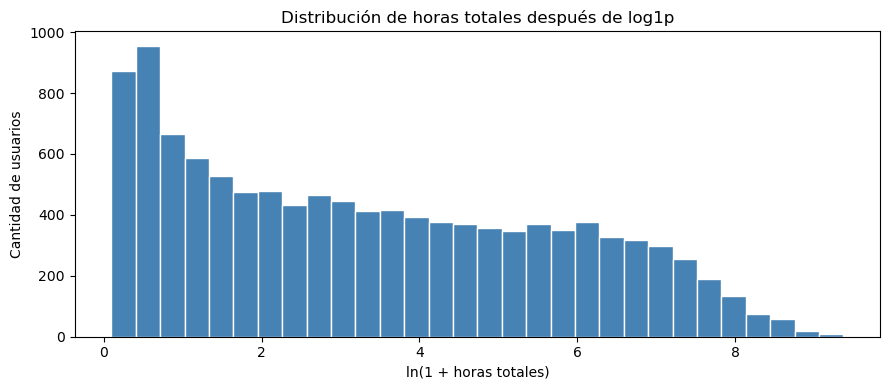

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))

plt.hist(
    usuarios_log['horas_totales'],
    bins=30,
    color='steelblue',
    edgecolor='white'
)

plt.title('Distribución de horas totales después de log1p')
plt.xlabel('ln(1 + horas totales)')
plt.ylabel('Cantidad de usuarios')
plt.tight_layout()
plt.show()

Se conservaron los valores altos porque no se identificó evidencia de que fueran errores. Se aplicó una transformación logarítmica log1p a las tres variables para comprimir las diferencias de magnitud, manteniendo todos los usuarios. Posteriormente se revisará el resultado antes de aplicar el escalado.

El gráfico permite distinguir mucho mejor la distribución: los usuarios ya no quedan amontonados visualmente en una sola barra. Aún hay más usuarios en los valores bajos, pero no necesitamos que la distribución tenga forma de campana para continuar.

Ahora aplicaremos StandardScaler a las tres columnas de usuarios_log.



In [36]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

usuarios_escalados = pd.DataFrame(
    scaler.fit_transform(usuarios_log),
    index=usuarios_log.index,
    columns=usuarios_log.columns
)

In [37]:
usuarios_escalados.agg(['mean', 'std']).round(3)

,horas_totales,juegos_jugados,juegos_comprados
mean,-0.0,-0.0,0.0
std,1.0,1.0,1.0


Después de la transformación logarítmica, se estandarizaron las tres variables para que tuvieran escalas comparables antes del clustering. Se conservaron por separado los datos originales para interpretar posteriormente los segmentos.

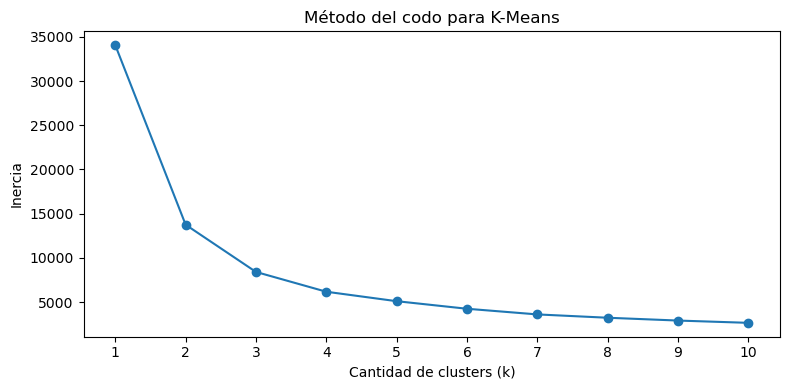

In [38]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inercias = []
valores_k = range(1, 11)

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modelo.fit(usuarios_escalados)
    inercias.append(modelo.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(valores_k, inercias, marker='o')
plt.title('Método del codo para K-Means')
plt.xlabel('Cantidad de clusters (k)')
plt.ylabel('Inercia')
plt.xticks(list(valores_k))
plt.tight_layout()
plt.show()

El método del codo sugirió explorar soluciones cercanas a tres o cuatro grupos, sin identificar un punto inequívoco. Se compararon soluciones de dos a seis clusters mediante el coeficiente de silueta, estimado sobre una muestra reproducible de 3.000 usuarios.

In [39]:
from sklearn.metrics import silhouette_score

resultados = []

for k in range(2, 7):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(usuarios_escalados)

    silueta = silhouette_score(
        usuarios_escalados,
        etiquetas,
        sample_size=3000,
        random_state=42
    )

    resultados.append({
        'k': k,
        'silueta': silueta
    })

comparacion = pd.DataFrame(resultados)

comparacion

,k,silueta
0,2,0.581568
1,3,0.470128
2,4,0.451557
3,5,0.447773
4,6,0.422131


In [40]:
modelo_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

etiquetas = modelo_kmeans.fit_predict(usuarios_escalados)


usuarios_clusters = usuarios.copy()
usuarios_clusters['cluster'] = etiquetas

print("Usuarios por cluster:")
print(usuarios_clusters['cluster'].value_counts().sort_index())

print("\nMedianas por cluster:")
print(
    usuarios_clusters.groupby('cluster')[
        ['horas_totales', 'juegos_jugados', 'juegos_comprados']
    ].median()
)

Usuarios por cluster:
cluster
0    2525
1    8825
Name: count, dtype: int64

Medianas por cluster:
         horas_totales  juegos_jugados  juegos_comprados
cluster                                                 
0                557.3            12.0              19.0
1                  7.8             1.0               1.0


Se seleccionó inicialmente una solución de dos clusters porque obtuvo la mayor silueta estimada entre las alternativas evaluadas, con un valor aproximado de 0,582. Esta elección se complementó con la revisión del tamaño y las características de los grupos.

A partir de las medianas de horas totales, juegos jugados y juegos comprados, se asignaron los siguientes nombres:

Cluster 0: «Jugadores con mayor actividad acumulada». Incluye 2.525 usuarios y presenta medianas de 557,3 horas, 12 juegos jugados y 19 juegos comprados.

Cluster 1: «Jugadores con menor actividad acumulada». Incluye 8.825 usuarios y presenta medianas de 7,8 horas, 1 juego jugado y 1 juego comprado.
image.jpg

Estos nombres describen diferencias relativas en la actividad acumulada registrada en el dataset; no indican frecuencia de juego ni permiten determinar si los usuarios siguen activos actualmente.

In [41]:
nombres = {
    0: 'Mayor actividad acumulada',
    1: 'Menor actividad acumulada'
}

usuarios_clusters['segmento'] = usuarios_clusters['cluster'].map(nombres)

### Recomendaciones de negocio

- Estrategia de marketing: para el cluster 0, «Jugadores con mayor actividad acumulada», se propone fidelización mediante recomendaciones personalizadas y novedades relacionadas con sus juegos. Para el cluster 1, «Jugadores con menor actividad acumulada», se busca incentivar la exploración de otros títulos.

- Promociones: el cluster 0 recibiría ofertas en expansiones, contenido adicional y paquetes de juegos relacionados. Para el cluster 1 se proponen pruebas gratuitas, descuentos de entrada y paquetes económicos.

- Prioridad de fidelización: se priorizaría inicialmente al cluster 0 por su mayor actividad acumulada, sin asumir que sea el más rentable. El cluster 1 recibiría campañas orientadas a aumentar su participación.

- Información adicional: fechas de sesiones y compras, antigüedad de la cuenta, gasto real, preferencias de género y respuesta a promociones. Esto permitiría diferenciar usuarios nuevos, ocasionales e inactivos, algo que los datos actuales no permiten determinar.